In [36]:
# Install packages
from pathlib import Path
import mne
import numpy as np
from scipy.io import loadmat

# Global variables setup
PATH = Path('/Users/emmaabecasis/Library/CloudStorage/GoogleDrive-abecasis@usc.edu/My Drive/Mi Game') # make sure this fits
# may have to edit, depending on file format

EEG_CHANNELS = [
"EEG F4", "EEG C4", "EEG P4", "EEG P3",
"EEG C3", "EEG F3", "EEG Pz",
]

In [2]:
# Import files
if PATH.is_dir():
    items = list(PATH.rglob("*"))

    edfs = [p for p in items if p.is_file() and p.suffix.lower() == ".edf"]
    print("EDF files found:", len(edfs))
    data_files = [str(file_path.resolve()) for file_path in edfs]

EDF files found: 30


In [10]:
# If using trigger hub/adding triggers in DSI-Streamer
event_id = {
  "pre_meditation": 1,
  "meditation": 2,
  "post_meditation": 3,
}

# We can also manually add annotations if using standardized procedure
annot = mne.Annotations(
    onset=[0, 60, 120], # Edit to match actual times in seconds
    duration=[60, 60, 60], # Edit to match actual durations in seconds
    description=["pre_meditation", "meditation", "post_meditation"],
  )

In [51]:
def load_edf(file_path):
    data = mne.io.read_raw_edf(file_path, preload=True)

    # Reference to left ear channel
    data.set_eeg_reference(ref_channels="EEG LE-Pz")

    # Standardize channel names
    rename_dict = {}
    for ch_name in data.ch_names:
        if '-Pz' in ch_name:
            rename_dict[ch_name] = ch_name.replace('-Pz', '')
        if ch_name == "Pz":
                  rename_dict[ch_name] = "EEG Pz"
    data.rename_channels(rename_dict)

    data.set_channel_types({
        "Event": "stim",
        "Ax": "misc",
        "Ay": "misc",
        "Az": "misc",
    })

    data.set_channel_types({ch: "eeg" for ch in EEG_CHANNELS})

    data.rename_channels(lambda name: name.removeprefix("EEG "))


    # create MNE raw object (should be channels x samples - otherwise need to transpose data)
    raw = mne.io.RawArray(data.get_data(), data.info)
    raw.set_annotations(annot)
    interactive_annot = raw.annotations

    # set locations of electrodes to match standard 10-20 system
    # montage = mne.channels.make_standard_montage("standard_1020")
    # raw.set_montage(montage, on_missing="raise")

    # visually inspect data - annotate bad time spans and channels
    # press A to enter annotation mode - close window to save annotations
    fig = raw.plot(scalings="auto", n_channels=7, duration=60)

    # band pass filter
    raw.filter(l_freq=0.5, h_freq=41)

    # downsample to 256 HA
    raw.resample(sfreq=256)

    return raw

# Artifact removal
from mne.preprocessing import ICA

def run_ica(raw):
    raw_ica = raw.copy().pick(picks="eeg")
    raw_ica.rename_channels(lambda name: name.removeprefix("EEG "))

    montage = mne.channels.make_standard_montage('standard_1020')
    raw_ica.set_montage(montage, on_missing="ignore")

    filt_raw = raw_ica.copy().filter(l_freq=1.0, h_freq=None).pick(picks="eeg")
    filt_raw.set_montage(raw_ica.get_montage())
    ica = ICA(max_iter="auto", random_state=97)
    ica.fit(filt_raw)
    ica.plot_sources(raw, show_scrollbars=False)
    ica.plot_components()
    return ica

# arbitrary epoch rejection criteria used; we can change if this doesn't fit our data
reject_criteria = dict(
    mag=3000e-15,  # 3000 fT
    grad=3000e-13,  # 3000 fT/cm
    eeg=100e-6,  # 100 µV
    eog=200e-6,   # 200 µV
)  

flat_criteria = dict(mag=1e-15, grad=1e-13, eeg=1e-6)  # 1 fT  # 1 fT/cm  # 1 µV

def segment_epochs(raw, epoch_duration=5):
    events = mne.find_events(raw, stim_channel="Trigger")

    # Keep only the pre-meditation, meditation, and post-meditation markers
    stage_codes = set(event_id.values())
    events = events[np.isin(events[:, 2], list(stage_codes))]
    events = events[np.argsort(events[:, 0])]

    sfreq = raw.info["sfreq"]
    samples_per_epoch = round(epoch_duration * sfreq)
    epoch_events = []

    for i, (stage_start, _, code) in enumerate(events):
        stage_end = (
            events[i + 1, 0]
            if i + 1 < len(events)
            else raw.first_samp + raw.n_times
        )

        # Add an epoch only if the entire epoch fits within this stage
        starts = np.arange(
            stage_start,
            stage_end - samples_per_epoch + 1,
            samples_per_epoch,
        )
        epoch_events.extend(
            [[sample, 0, code] for sample in starts]
        )

    if not epoch_events:
        raise ValueError("No complete 5-second epochs fit within the marked stages.")

    return mne.Epochs(
        raw,
        np.asarray(epoch_events, dtype=int),
        event_id=event_id,
        tmin=0,
        tmax=(samples_per_epoch - 1) / sfreq,
        reject = reject_criteria,
        flat = flat_criteria,
        baseline=None,
        preload=True,
    )

def quality_check(epochs, participant_id):
    original_epoch_count = len(epochs.events)
    epochs.drop_bad()
    retained_epoch_count = len(epochs)
    rejected_epoch_count = original_epoch_count - retained_epoch_count
    
    if original_epoch_count:
        rejected_percentage = (100* rejected_epoch_count / original_epoch_count)
    else:
        rejected_percentage = np.nan
    
    print(f"\n{participant_id} quality summary")
    print(f"Original epochs: {original_epoch_count}")
    print(f"Retained epochs: {retained_epoch_count}")
    print(f"Rejected epochs: {rejected_epoch_count}")
    print(f"Rejected percentage: {rejected_percentage:.1f}%")
    
    epochs.plot_drop_log()
    epochs.plot(n_epochs=min(10, len(epochs)), scalings="auto")
    epochs.compute_psd().plot()
 
    return epochs


In [8]:
%pip install mne-qt-browser PySide6


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 577.5/577.5 kB 17.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.5/90.5 MB 21.3 MB/s  0:00:04m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.0/116.0 MB 19.5 MB/s  0:00:05m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 20.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.8/249.8 MB 14.4 MB/s  0:00:17m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━ 3/6 [PySide6_Addons]ERROR: Could not install packages due to an OSError: [Errno 28] No space left on device

   ━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━ 3/6 [PySide6_Addons]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [16]:
raw_test = load_edf(data_files[0])
print(raw_test.info)


Extracting EDF parameters from /Users/emmaabecasis/Library/CloudStorage/GoogleDrive-abecasis@usc.edu/.shortcut-targets-by-id/1jU-wqGo09vdL3JtwMwmFZ4IEUJLqJfB9/Mi Game/04_08_26_mi_outsideAhmanson_andy_raw.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 166199  =      0.000 ...   553.997 secs...
EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Creating RawArray with float64 data, n_channels=13, n_times=166200
    Range : 0 ... 166199 =      0.000 ...   553.997 secs
Ready.
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 41 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 41.00 Hz
- Up

Channels marked as bad:
none


/Users/emmaabecasis/Library/CloudStorage/GoogleDrive-abecasis@usc.edu/.shortcut-targets-by-id/1jU-wqGo09vdL3JtwMwmFZ4IEUJLqJfB9/Mi Game/04_08_26_mi_outsideAhmanson_andy_raw.edf
Extracting EDF parameters from /Users/emmaabecasis/Library/CloudStorage/GoogleDrive-abecasis@usc.edu/.shortcut-targets-by-id/1jU-wqGo09vdL3JtwMwmFZ4IEUJLqJfB9/Mi Game/04_08_26_mi_outsideAhmanson_andy_raw.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 166199  =      0.000 ...   553.997 secs...
EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Creating RawArray with float64 data, n_channels=13, n_times=166200
    Range : 0 ... 166199 =      0.000 ...   553.997 secs
Ready.


/var/folders/5b/bf1nt6ln2y71xfnrhccqvn7r0000gn/T/ipykernel_74333/3056163724.py:16: RuntimeWarning: The unit for channel(s) Ax, Ay, Az has changed from V to NA.
  data.set_channel_types({


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 41 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 41.00 Hz
- Upper transition bandwidth: 10.25 Hz (-6 dB cutoff frequency: 46.12 Hz)
- Filter length: 1981 samples (6.603 s)

Finding events on: Trigger, Event
50 events found on stim channel Trigger
Event IDs: [1 2]
Finding events on: Trigger, Event
50 events found on stim channel Trigger
Event IDs: [1 2]
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 

/var/folders/5b/bf1nt6ln2y71xfnrhccqvn7r0000gn/T/ipykernel_74333/3056163724.py:56: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = mne.channels.make_standard_montage('standard_1020')


Fitting ICA took 0.5s.
Creating RawArray with float64 data, n_channels=7, n_times=141824
    Range : 0 ... 141823 =      0.000 ...   553.996 secs
Ready.


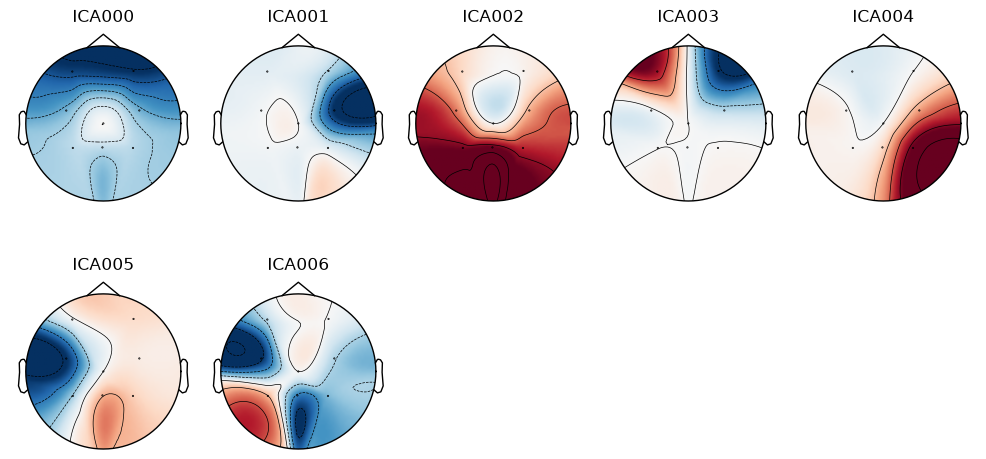

Creating RawArray with float64 data, n_channels=7, n_times=141824
    Range : 0 ... 141823 =      0.000 ...   553.996 secs
Ready.
Applying ICA to Raw instance
    Transforming to ICA space (7 components)
    Zeroing out 2 ICA components
    Projecting back using 8 PCA components
Finding events on: Trigger
50 events found on stim channel Trigger
Event IDs: [1 2]


ValueError: No matching events found for post_meditation (event id 3)

Channels marked as bad:
none


In [52]:
# install mne-qt-browser
mne.viz.set_browser_backend("qt")

icas = []
raws = []
epochs_list = []

for i, file in enumerate(data_files):
    print(file)
    raw = load_edf(file)
    raws.append(raw)
    ica_obj = run_ica(raw)
    icas.append(ica_obj)

    if i == 0:
        ica_obj.plot_sources(raw, show_scrollbars=False)

        # manually select which components to exclude
        ica_obj.exclude = [0, 1]  # example: exclude the first two components

    else:
        raw_zero = raws[0]
        ica_obj = icas[0]
        eog_inds, eog_scores = ica_obj.find_bads_eog(raw_zero, ch_name="Fpz")
        corrmap(icas, template=(0, eog_inds[0]))
        ica_obj = run_ica(raw)
        icas[i] = ica_obj

    raw = ica_obj.apply(raw)
    raws[i] = raw

    epochs = segment_epochs(raw)
    quality_check(epochs, file)

    epochs_list.append(epochs)